In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
    HAS_SEABORN = True
except ImportError:
    HAS_SEABORN = False

project_root = Path.cwd().resolve()
data_path = None

for base in [project_root, project_root / "notebook", project_root.parent]:
    candidate = base / "data" / "raw.csv"
    if candidate.exists():
        data_path = candidate
        break

if data_path is None:
    raise FileNotFoundError("File raw.csv tidak ditemukan. Pastikan file ada di folder data.")

df = pd.read_csv(data_path)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].str.strip().str.lower().map({"yes": 1, "no": 0})

print("Shape dataset:", df.shape)
print("\nKolom dataset:")
print(df.columns.tolist())
print("\nTipe data:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())

df.head()

Shape dataset: (7043, 21)

Kolom dataset:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Tipe data:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

Missing values:
cus

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:
# Ringkasan numerik
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Statistik numerik:")
print(df[numeric_cols].describe().T)

# Distribusi target
print("\nProporsi churn:")
print(df["Churn"].value_counts(normalize=True).round(4))

# Distribusi kategorikal utama
cat_cols = [c for c in df.columns if c not in numeric_cols + ["customerID", "Churn"]]
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(10))

# Analisa churn per kategori
for col in cat_cols:
    if df[col].nunique() <= 10:
        table = pd.crosstab(df[col], df["Churn"])
        print(f"\nCross-tab {col}:")
        print(table)


Statistik numerik:
                 count         mean          std    min     25%       50%  \
SeniorCitizen   7043.0     0.162147     0.368612   0.00    0.00     0.000   
tenure          7043.0    32.371149    24.559481   0.00    9.00    29.000   
MonthlyCharges  7043.0    64.761692    30.090047  18.25   35.50    70.350   
TotalCharges    7032.0  2283.300441  2266.771362  18.80  401.45  1397.475   
Churn           7043.0     0.265370     0.441561   0.00    0.00     0.000   

                      75%      max  
SeniorCitizen      0.0000     1.00  
tenure            55.0000    72.00  
MonthlyCharges    89.8500   118.75  
TotalCharges    3794.7375  8684.80  
Churn              1.0000     1.00  

Proporsi churn:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64

--- gender ---
gender
Male      3555
Female    3488
Name: count, dtype: int64

--- Partner ---
Partner
No     3641
Yes    3402
Name: count, dtype: int64

--- Dependents ---
Dependents
No     4933
Yes    2110
Name: c

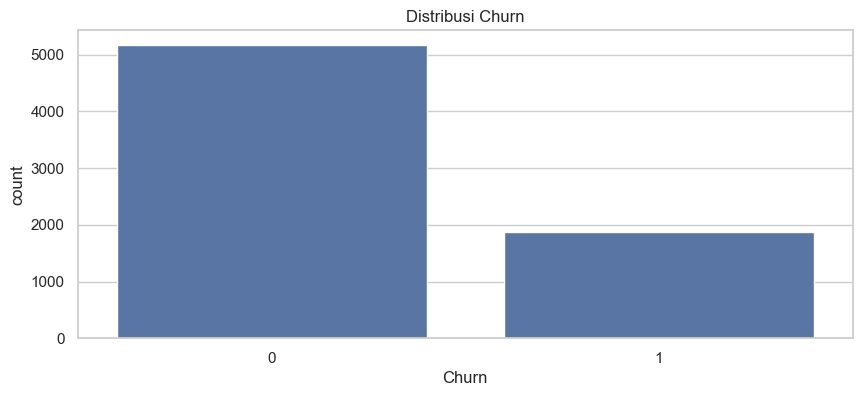

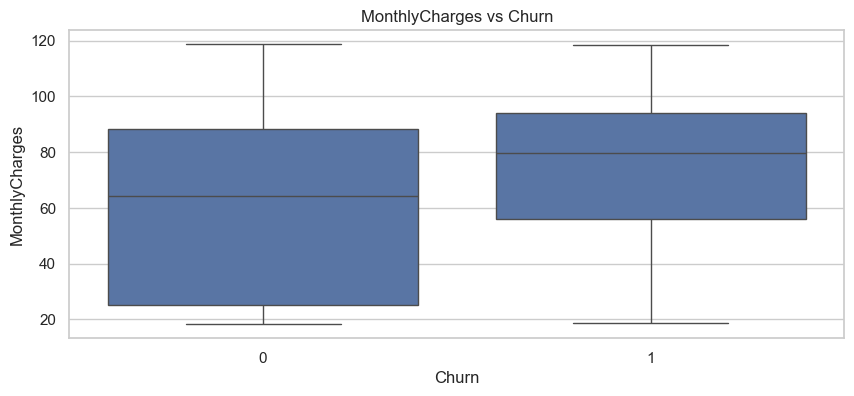

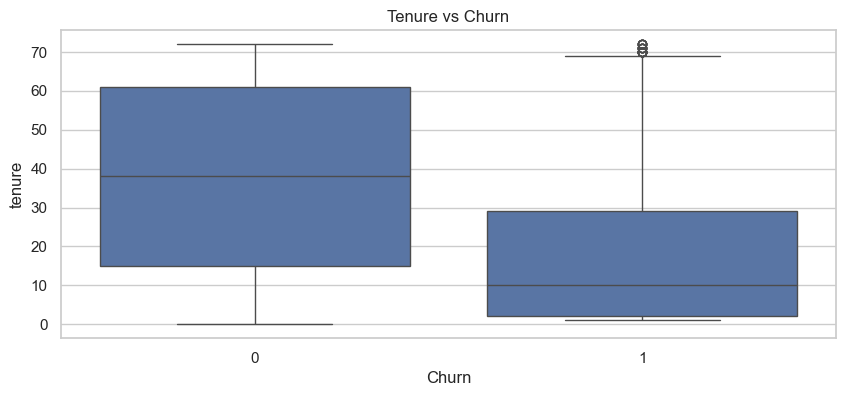

In [3]:
# Visualisasi sederhana
if HAS_SEABORN:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df, x="Churn")
    plt.title("Distribusi Churn")
    plt.show()

    plt.figure(figsize=(10, 4))
    sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
    plt.title("MonthlyCharges vs Churn")
    plt.show()

    plt.figure(figsize=(10, 4))
    sns.boxplot(data=df, x="Churn", y="tenure")
    plt.title("Tenure vs Churn")
    plt.show()
else:
    print("Seaborn tidak tersedia, lewati visualisasi.")


Berdasarkan boxplot, pelanggan yang mengalami churn cenderung memiliki MonthlyCharges yang lebih tinggi dibandingkan pelanggan yang tidak mengalami churn. Selain itu, pelanggan yang churn memiliki tenure yang jauh lebih rendah, dengan median sekitar 10 bulan dibandingkan sekitar 38 bulan pada pelanggan yang tidak churn. Hal ini mengindikasikan bahwa MonthlyCharges dan tenure berpotensi menjadi fitur yang relevan dalam memprediksi churn.

<Figure size 1400x600 with 0 Axes>

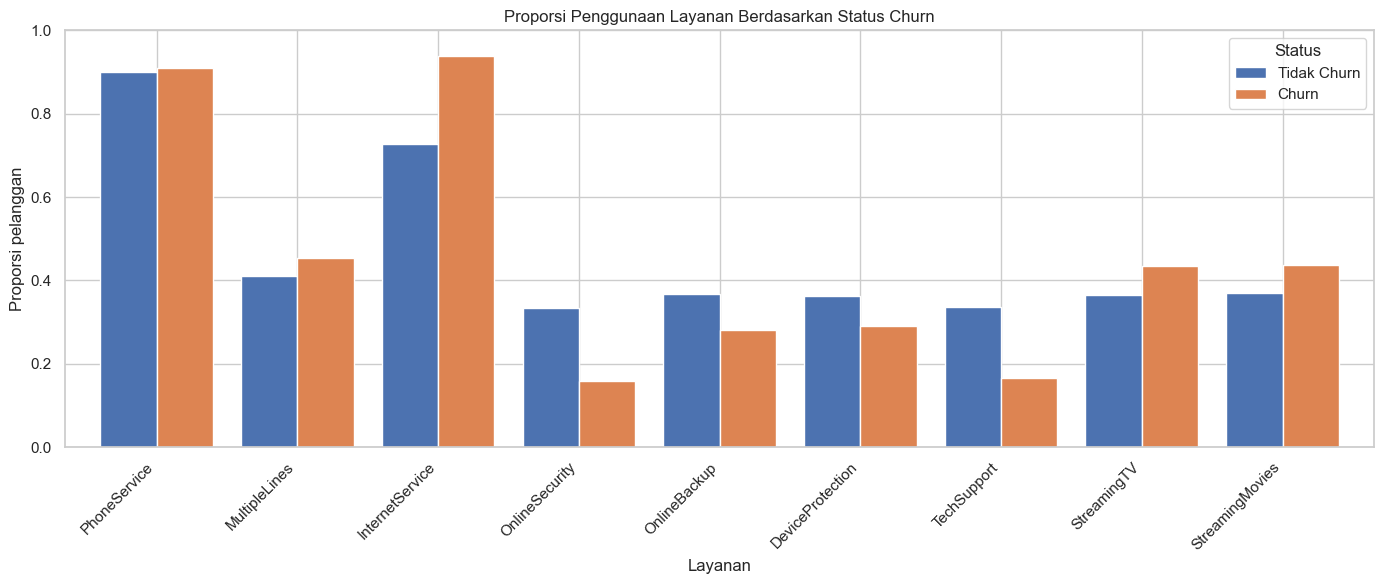

In [4]:
# Plot proporsi penggunaan layanan per status churn
service_cols = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]

def uses_service(value):
    if pd.isna(value):
        return False
    return str(value).strip().lower() not in {"no", "no internet service", "no phone service"}

service_usage = []
for col in service_cols:
    churn_0 = df.loc[df["Churn"] == 0, col].apply(uses_service).mean()
    churn_1 = df.loc[df["Churn"] == 1, col].apply(uses_service).mean()
    service_usage.append((col, churn_0, churn_1))

service_usage_df = pd.DataFrame(service_usage, columns=["service", "Tidak Churn", "Churn"])
service_usage_df = service_usage_df.set_index("service")

plt.figure(figsize=(14, 6))
service_usage_df.plot(kind="bar", figsize=(14, 6), width=0.8)
plt.title("Proporsi Penggunaan Layanan Berdasarkan Status Churn")
plt.ylabel("Proporsi pelanggan")
plt.xlabel("Layanan")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.legend(title="Status")
plt.tight_layout()
plt.show()


In [5]:
# Copy data
model_df = df.drop(columns=["customerID"]).copy()

# Pastikan Churn numerik
model_df["Churn"] = model_df["Churn"].astype(float)

# One-hot encoding hanya untuk fitur kategorikal
object_cols = model_df.select_dtypes(include=["object"]).columns.tolist()

model_df = pd.get_dummies(
    model_df,
    columns=object_cols,
    drop_first=True
)

# Pisahkan fitur dan target
features = model_df.drop(columns=["Churn"])
target = model_df["Churn"]

# Hitung korelasi
corr = features.corrwith(target)

# Buat tabel korelasi
corr_df = pd.DataFrame({
    "Correlation": corr,
    "AbsCorrelation": corr.abs()
}).sort_values(
    "AbsCorrelation",
    ascending=False
)

print("Top fitur yang paling berkorelasi dengan Churn:")
print(corr_df.head(20))

Top fitur yang paling berkorelasi dengan Churn:
                                      Correlation  AbsCorrelation
tenure                                  -0.352229        0.352229
InternetService_Fiber optic              0.308020        0.308020
Contract_Two year                       -0.302253        0.302253
PaymentMethod_Electronic check           0.301919        0.301919
InternetService_No                      -0.227890        0.227890
OnlineSecurity_No internet service      -0.227890        0.227890
DeviceProtection_No internet service    -0.227890        0.227890
TechSupport_No internet service         -0.227890        0.227890
StreamingMovies_No internet service     -0.227890        0.227890
StreamingTV_No internet service         -0.227890        0.227890
OnlineBackup_No internet service        -0.227890        0.227890
TotalCharges                            -0.199484        0.199484
MonthlyCharges                           0.193356        0.193356
PaperlessBilling_Yes        

Pelanggan dengan tenure lebih pendek, biaya bulanan lebih tinggi, menggunakan Fiber optic, dan menggunakan Electronic check cenderung memiliki keterkaitan lebih tinggi dengan churn. Sebaliknya, pelanggan dengan kontrak satu atau dua tahun, tenure lebih panjang, serta layanan seperti OnlineSecurity dan TechSupport cenderung memiliki keterkaitan lebih rendah dengan churn.

In [6]:
# ...existing code...
df = pd.read_csv(data_path)

# Normalisasi string dan hilangkan whitespace
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].astype(str).str.strip()

# Ubah empty string menjadi NaN supaya bisa dideteksi
df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

# Cek duplikat
duplicate_count = df.duplicated().sum()
print("Jumlah baris duplikat:", duplicate_count)
if duplicate_count:
    df = df.drop_duplicates()
    print("Duplikat dihapus.")

# Cek missing dan format salah
print("\nMissing values per kolom:")
missing = df.isna().sum()
print(missing[missing > 0])

# Pastikan TotalCharges numerik
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
wrong_total = df["TotalCharges"].isna().sum()
print("\nTotalCharges invalid atau kosong:", wrong_total)

# Pastikan Churn valid
df["Churn"] = df["Churn"].str.strip().str.lower().map({"yes": 1, "no": 0})
invalid_churn = df["Churn"].isna().sum()
print("Churn invalid atau kosong:", invalid_churn)

# Bersihkan data bermasalah
if invalid_churn:
    df = df.dropna(subset=["Churn"])
    print(f"{invalid_churn} baris dengan nilai Churn tidak valid dihapus.")

# Isi missing numeric dengan median
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
for col in numeric_cols:
    if df[col].isna().any():
        median = df[col].median()
        df[col].fillna(median, inplace=True)
        print(f"Missing pada kolom numerik '{col}' diisi dengan median ({median}).")

# Isi missing kategorikal dengan modus
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()
for col in cat_cols:
    if df[col].isna().any():
        mode = df[col].mode(dropna=True)
        if not mode.empty:
            df[col].fillna(mode[0], inplace=True)
            print(f"Missing pada kolom kategorikal '{col}' diisi dengan modus ('{mode[0]}').")

print("\nShape dataset setelah cleaning:", df.shape)
print("Missing values setelah cleaning:", df.isna().sum().sum())
# ...existing code...

Jumlah baris duplikat: 0

Missing values per kolom:
TotalCharges    11
dtype: int64

TotalCharges invalid atau kosong: 11
Churn invalid atau kosong: 0
Missing pada kolom numerik 'TotalCharges' diisi dengan median (1397.475).

Shape dataset setelah cleaning: (7043, 21)
Missing values setelah cleaning: 0


C:\Users\62812\AppData\Local\Temp\ipykernel_15496\3244260472.py:43: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median, inplace=True)


In [7]:
cleaned_path = project_root / "data" / "cleaned.csv"
cleaned_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(cleaned_path, index=False)
print(f"Data bersih disimpan ke: {cleaned_path}")

Data bersih disimpan ke: C:\Users\62812\OneDrive\Documents\Project\Churn Prediction\notebook\data\cleaned.csv
